# Tópico 12 - Polos, Zeros e Estabilidade no Plano-s

## Visão Geral e Objetivos
Neste notebook, investigamos o mapeamento de **Polos e Zeros no Plano-s** e sua relação direta com a **Estabilidade de Sistemas Contínuos (LTI)**. Os principais objetivos são:
1. **Diagrama de Polos e Zeros (PZ Map)**: Plotar a localização das raízes do numerador (zeros, $\circ$) e do denominador (polos, $\times$) no plano complexo $s = \sigma + j\omega$.
2. **Critério de Estabilidade BIBO (Bounded-Input Bounded-Output)**: Demonstrar que a estabilidade assintótica exige que todos os polos residam estritamente no semiplano esquerdo ($\text{Re}\{p\} < 0$).
3. **Influência dos Zeros**: Analisar o impacto da adição de zeros no semiplano esquerdo (aceleração do tempo de subida / aumento do sobressinal) e de zeros de fase não-mínima no semiplano direito (efeito de inversão inicial / *undershoot*).
4. **Gerenciamento de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Mapeamento de Polos e Zeros no Plano Complexo $s$

Consideramos três sistemas LTI contínuos com diferentes configurações de polos para avaliar o comportamento estático e dinâmico:
1. **Sistema Estável**: Polos complexos conjugados no semiplano esquerdo ($p_{1,2} = -1 \pm j2$).
   $$H_1(s) = \frac{5}{s^2 + 2s + 5}$$
2. **Sistema Marginalmente Estável**: Polos no eixo imaginário $j\omega$ ($p_{1,2} = \pm j2$).
   $$H_2(s) = \frac{4}{s^2 + 4}$$
3. **Sistema Instável**: Polos no semiplano direito ($p_{1,2} = +0.5 \pm j2$).
   $$H_3(s) = \frac{4.25}{s^2 - s + 4.25}$$

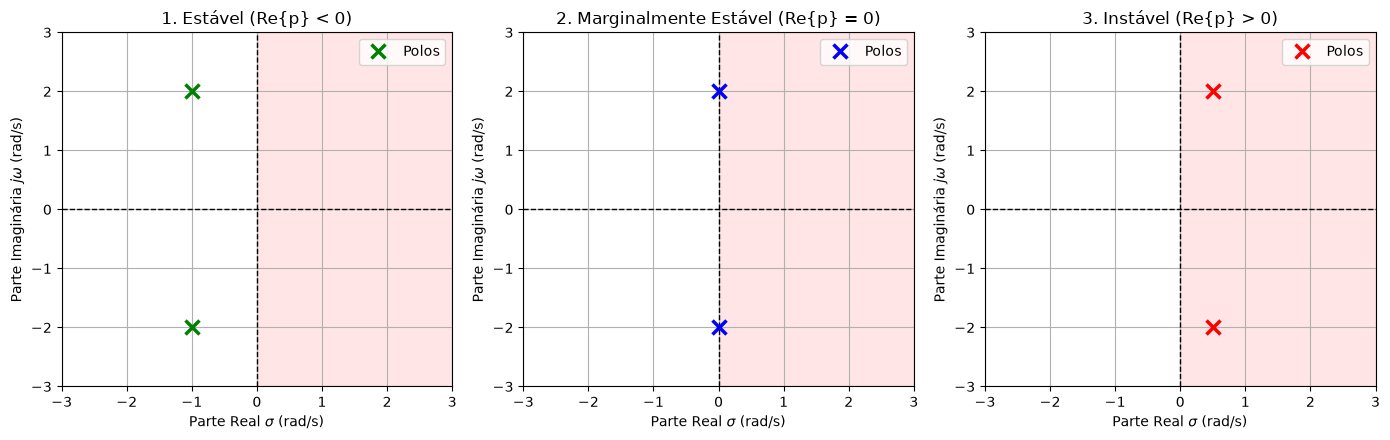

In [2]:
# Definição das funções de transferência
sys1 = signal.lti([5.0], [1.0, 2.0, 5.0])       # Estável
sys2 = signal.lti([4.0], [1.0, 0.0, 4.0])       # Marginalmente Estável
sys3 = signal.lti([4.25], [1.0, -1.0, 4.25])   # Instável

sistemas = [sys1, sys2, sys3]
titulos = ['1. Estável (Re{p} < 0)', '2. Marginalmente Estável (Re{p} = 0)', '3. Instável (Re{p} > 0)']
cores = ['green', 'blue', 'red']

fig1, axs1 = plt.subplots(1, 3, figsize=(14, 4.5))

for idx, sys in enumerate(sistemas):
    polos = sys.poles
    zeros = sys.zeros
    
    # Eixos real e imaginário
    axs1[idx].axhline(0, color='black', linestyle='--', linewidth=1)
    axs1[idx].axvline(0, color='black', linestyle='--', linewidth=1)
    
    # Hachurar a região de instabilidade (Re{s} > 0)
    axs1[idx].axvspan(0, 3, color='red', alpha=0.1)
    
    # Plotar Polos (X) e Zeros (O)
    if len(polos) > 0:
        axs1[idx].plot(np.real(polos), np.imag(polos), 'x', color=cores[idx], markersize=10, markeredgewidth=2.5, label='Polos')
    if len(zeros) > 0:
        axs1[idx].plot(np.real(zeros), np.imag(zeros), 'o', color=cores[idx], markersize=8, markerfacecolor='none', markeredgewidth=2, label='Zeros')
        
    axs1[idx].set_title(titulos[idx])
    axs1[idx].set_xlabel(r'Parte Real $\sigma$ (rad/s)')
    axs1[idx].set_ylabel(r'Parte Imaginária $j\omega$ (rad/s)')
    axs1[idx].set_xlim(-3, 3)
    axs1[idx].set_ylim(-3, 3)
    axs1[idx].grid(True)
    axs1[idx].legend(loc='upper right')

plt.tight_layout()
fig1.savefig("grafico_mapa_polos_zeros.png")
plt.show()

## 2. Resposta Temporal e Efeito da Adição de Zeros

Abaixo, avaliamos:
1. **Resposta ao Degrau para os 3 Casos de Estabilidade**: Comprovação da convergência no semiplano esquerdo vs. oscilação mantida no eixo $j\omega$ vs. divergência no semiplano direito.
2. **Efeito da Adição de Zeros**:
   - **Zero de Fase Mínima ($s = -2$)**: Acelera a resposta e aumenta o sobressinal.
     $$H_{z1}(s) = \frac{2.5(s + 2)}{s^2 + 2s + 5}$$
   - **Zero de Fase Não-Mínima ($s = +2$)**: Introduz uma resposta inversa inicial (*undershoot*).
     $$H_{z2}(s) = \frac{-2.5(s - 2)}{s^2 + 2s + 5}$$

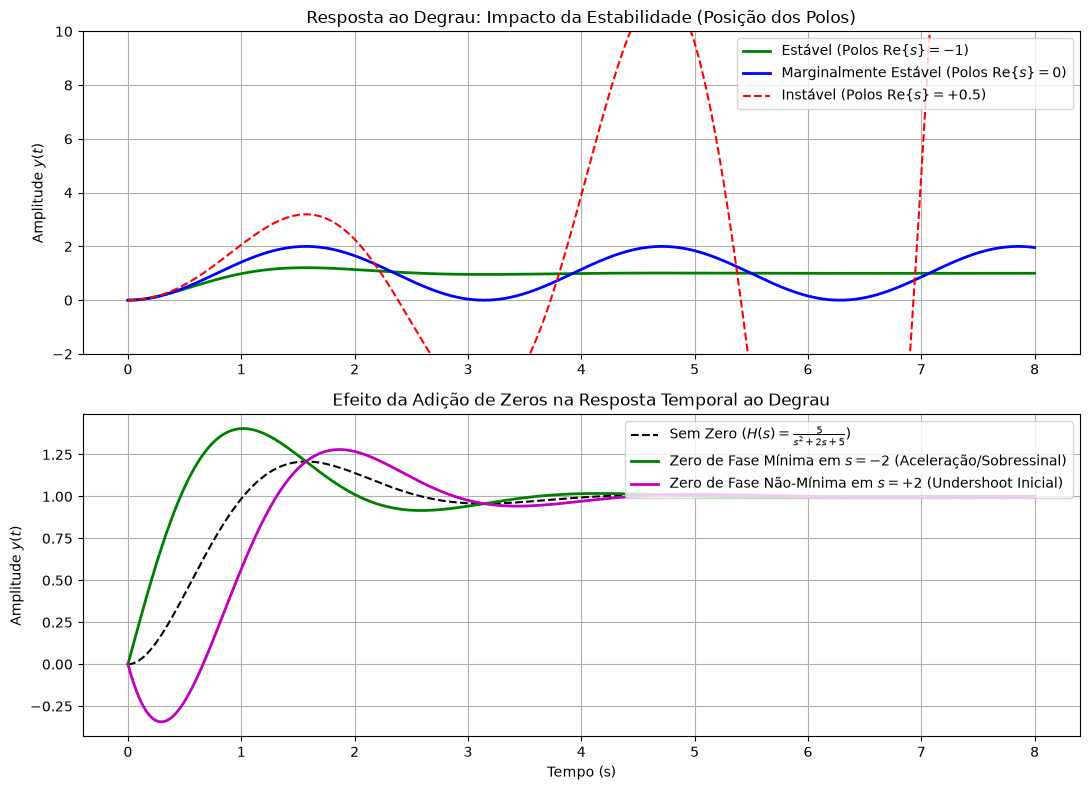

In [3]:
t1 = np.linspace(0, 8, 1000)

# Simulação das respostas ao degrau para os 3 tipos de estabilidade
_, y1 = signal.step(sys1, T=t1)
_, y2 = signal.step(sys2, T=t1)
_, y3 = signal.step(sys3, T=t1)

# Definição de sistemas com zeros (Fase Mínima vs. Fase Não-Mínima)
sys_z1 = signal.lti([2.5, 5.0], [1.0, 2.0, 5.0])    # Zero em s = -2
sys_z2 = signal.lti([-2.5, 5.0], [1.0, 2.0, 5.0])   # Zero em s = +2 (Fase não-mínima)

_, y_z1 = signal.step(sys_z1, T=t1)
_, y_z2 = signal.step(sys_z2, T=t1)

fig2, (ax_est, ax_zeros) = plt.subplots(2, 1, figsize=(11, 8))

# Subplot 1: Estabilidade segundo a posição dos polos
ax_est.plot(t1, y1, 'g-', linewidth=2, label=r'Estável (Polos $\text{Re}\{s\} = -1$)')
ax_est.plot(t1, y2, 'b-', linewidth=2, label=r'Marginalmente Estável (Polos $\text{Re}\{s\} = 0$)')
ax_est.plot(t1, y3, 'r--', linewidth=1.5, label=r'Instável (Polos $\text{Re}\{s\} = +0.5$)')
ax_est.set_title('Resposta ao Degrau: Impacto da Estabilidade (Posição dos Polos)')
ax_est.set_ylabel('Amplitude $y(t)$')
ax_est.set_ylim(-2, 10)
ax_est.grid(True)
ax_est.legend(loc='upper right')

# Subplot 2: Efeito dos Zeros na Resposta Temporal
ax_zeros.plot(t1, y1, 'k--', linewidth=1.5, label=r'Sem Zero ($H(s) = \frac{5}{s^2+2s+5}$)')
ax_zeros.plot(t1, y_z1, 'g-', linewidth=2, label=r'Zero de Fase Mínima em $s = -2$ (Aceleração/Sobressinal)')
ax_zeros.plot(t1, y_z2, 'm-', linewidth=2, label=r'Zero de Fase Não-Mínima em $s = +2$ (Undershoot Inicial)')
ax_zeros.set_title('Efeito da Adição de Zeros na Resposta Temporal ao Degrau')
ax_zeros.set_xlabel('Tempo (s)')
ax_zeros.set_ylabel('Amplitude $y(t)$')
ax_zeros.grid(True)
ax_zeros.legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_estabilidade_plano_s.png")
plt.show()

## 3. Síntese dos Resultados sobre Polos, Zeros e Estabilidade
- **Condição Necessária e Suficiente para Estabilidade**: Todos os polos do sistema contínuo devem possuir parte real estritamente negativa ($\text{Re}\{p_k\} < 0$).
- **Polos no Eixo Imaginário**: Polos simples no eixo $j\omega$ levam à estabilidade marginal (oscilações sustentadas de amplitude constante).
- **Papel dos Zeros**: A adição de zeros não altera os expoentes de atenuação temporal (ditados exclusivamente pelos polos), mas modifica os coeficientes de ponderação (resíduos) da resposta. Zeros no semiplano esquerdo aumentam a velocidade inicial, enquanto zeros no semiplano direito causam o fenômeno de inversão inicial (*undershoot*).